## Импорты и загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import uniform, randint

RANDOM_STATE = 42

# Загружаем данные (объединяем красное и белое вино)
url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

red = pd.read_csv(url_red, sep=';')
white = pd.read_csv(url_white, sep=';')
red['type'] = 0
white['type'] = 1
df = pd.concat([red, white], ignore_index=True)

X = df.drop(columns=['quality'])
y = df['quality']

# Разбиваем так же, как в Лабораторной №1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

## Исходная модель 

In [2]:
# Исходная модель (baseline)
gb_baseline = GradientBoostingRegressor(random_state=RANDOM_STATE)

# Замеряем время обучения
start_time = time.time()
# Считаем CV score на train (5 фолдов)
cv_scores_baseline = cross_val_score(gb_baseline, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
cv_rmse_baseline = -cv_scores_baseline.mean()
time_baseline = time.time() - start_time

# Оцениваем на test (только для записи базового результата, пока не трогаем для настройки)
gb_baseline.fit(X_train, y_train)
test_pred_baseline = gb_baseline.predict(X_test)
test_rmse_baseline = np.sqrt(mean_squared_error(y_test, test_pred_baseline))

print(f"=== Исходная модель (Baseline) ===")
print(f"CV RMSE (на train): {cv_rmse_baseline:.4f} ± {cv_scores_baseline.std():.4f}")
print(f"Test RMSE: {test_rmse_baseline:.4f}")
print(f"Время CV: {time_baseline:.2f} сек.")

=== Исходная модель (Baseline) ===
CV RMSE (на train): 0.6863 ± 0.0160
Test RMSE: 0.6784
Время CV: 2.81 сек.


 Это наш baseline для лабораторной

## Выбор гиперпараметров и их описание

Выбранные гиперпараметры для Gradient Boosting Regressor:

* n_estimators — количество деревьев в ансамбле. Больше деревьев → сложнее модель, риск переобучения, но точнее. Диапазон: [50, 300]. (Шаг 50).

* learning_rate — "шаг" обучения. Определяет, насколько сильно каждое новое дерево влияет на результат. Меньше → нужно больше деревьев, но лучше обобщение. Диапазон: [0.01, 0.1, 0.2, 0.3].

* max_depth — глубина каждого дерева. Глубокие деревья ловят сложные взаимодействия, но переобучаются. Диапазон: [3, 5, 7].

* min_samples_leaf — минимальное количество объектов в листе. Регуляризатор: большие значения сглаживают модель. Диапазон: [1, 3, 5, 10].

Гипотеза: Увеличение n_estimators и max_depth повышает сложность модели, но после определенного порога начнется переобучение (CV RMSE упадет, но разрыв с Test вырастет). Увеличение learning_rate требует уменьшения n_estimators.

## Grid Search

In [3]:
# Сетка параметров
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 5],
    'min_samples_leaf': [1, 5]
}

# Инициализация GridSearchCV
grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Запуск
start_time = time.time()
grid_search.fit(X_train, y_train)
time_grid = time.time() - start_time

# Результаты
grid_best_rmse = -grid_search.best_score_
print(f"=== Grid Search ===")
print(f"Проверено комбинаций: {len(grid_search.cv_results_['params'])}")
print(f"Время выполнения: {time_grid:.2f} сек.")
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший CV RMSE: {grid_best_rmse:.4f}")

=== Grid Search ===
Проверено комбинаций: 36
Время выполнения: 24.57 сек.
Лучшие параметры: {'learning_rate': 0.2, 'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 150}
Лучший CV RMSE: 0.6476


**Вывод:** Grid Search нашёл более сложную конфигурацию модели, чем дефолтная. Увеличение глубины деревьев (max_depth=5 вместо 3) позволяет ловить более сложные нелинейные взаимодействия между признаками (например, сочетание алкоголя и кислотности). Увеличение learning_rate до 0.2 и n_estimators до 150 даёт более быстрый и точный процесс обучения. Важно, что улучшение на кросс-валидации не сопровождается переобучением: CV RMSE снизился, а не вырос. min_samples_leaf=1 (значение по умолчанию) оказалось оптимальным — регуляризация через размер листа не понадобилась.

## Random Search

In [4]:
from scipy.stats import uniform, randint

param_dist = {
    'n_estimators': randint(50, 300),
    'learning_rate': uniform(0.01, 0.2), # от 0.01 до 0.21
    'max_depth': randint(3, 8),         # от 3 до 7
    'min_samples_leaf': randint(1, 10)  # от 1 до 9
}

random_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=len(grid_search.cv_results_['params']), # СТОЛЬКО ЖЕ, сколько в Grid
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()
random_search.fit(X_train, y_train)
time_random = time.time() - start_time

random_best_rmse = -random_search.best_score_
print(f"=== Random Search ===")
print(f"Проверено комбинаций: {len(random_search.cv_results_['params'])}")
print(f"Время выполнения: {time_random:.2f} сек.")
print(f"Лучшие параметры: {random_search.best_params_}")
print(f"Лучший CV RMSE: {random_best_rmse:.4f}")

=== Random Search ===
Проверено комбинаций: 36
Время выполнения: 43.78 сек.
Лучшие параметры: {'learning_rate': np.float64(0.08416365043965326), 'max_depth': 7, 'min_samples_leaf': 3, 'n_estimators': 221}
Лучший CV RMSE: 0.6314


**Вывод:** Random Search нашёл лучшее качество (CV RMSE на 0.016 ниже). Причина: Grid Search ограничен дискретной сеткой и не может проверить значения «между» узлами (например, learning_rate=0.084 или n_estimators=221). Random Search исследует непрерывные диапазоны и за те же 36 итераций покрывает более разнообразные области пространства, что позволяет найти более удачную комбинацию.

Random Search работал дольше (43.78 сек против 24.57 сек). Это объясняется тем, что он случайно выбрал более сложные комбинации (n_estimators=221, max_depth=7), которые требуют больше времени на обучение. Это не недостаток метода, а следствие более широкого исследования пространства.

Когда Random Search предпочтительнее Grid Search:
* Когда пространство гиперпараметров большое (много параметров или широкие диапазоны) — полный перебор становится вычислительно невозможным.
* Когда не все параметры одинаково важны — Random Search эффективнее «нащупывает» ключевые.
* Когда значения параметров непрерывны (например, learning_rate) — Grid Search вынужден их дискретизировать, теряя потенциально лучшие точки.
* Когда бюджет ограничен — Random Search даёт больше шансов найти хорошее решение за меньшее число итераций.

Grid Search предпочтительнее, когда пространство маленькое и мы точно знаем «узкие» диапазоны, где лежит оптимум.

## Итоговое сравнение

In [5]:
# 1. Лучшая модель из Grid Search
best_grid_model = grid_search.best_estimator_
test_pred_grid = best_grid_model.predict(X_test)
test_rmse_grid = np.sqrt(mean_squared_error(y_test, test_pred_grid))

# 2. Лучшая модель из Random Search
best_random_model = random_search.best_estimator_
test_pred_random = best_random_model.predict(X_test)
test_rmse_random = np.sqrt(mean_squared_error(y_test, test_pred_random))

print("=== Итоговое сравнение ===")
print(f"Baseline:      CV RMSE = {cv_rmse_baseline:.4f} | Test RMSE = {test_rmse_baseline:.4f}")
print(f"Grid Search:   CV RMSE = {grid_best_rmse:.4f} | Test RMSE = {test_rmse_grid:.4f}")
print(f"Random Search: CV RMSE = {random_best_rmse:.4f} | Test RMSE = {test_rmse_random:.4f}")

=== Итоговое сравнение ===
Baseline:      CV RMSE = 0.6863 | Test RMSE = 0.6784
Grid Search:   CV RMSE = 0.6476 | Test RMSE = 0.6419
Random Search: CV RMSE = 0.6314 | Test RMSE = 0.6180


**Вывод:** Random Search улучшил Test RMSE на 0.0604 относительно baseline (с 0.6784 до 0.6180), Grid Search — на 0.0365 (с 0.6784 до 0.6419). В относительных величинах Random Search дал улучшение около 9%, Grid Search — около 5%. Это существенное улучшение для задачи регрессии на Wine Quality.

Совпадает ли улучшение на CV с результатом на Test: да, совпадает почти идеально. Во всех трёх моделях CV RMSE и Test RMSE различаются не более чем на 0.013. Порядок моделей сохраняется (Baseline < Grid < Random) и на кросс-валидации, и на тесте. Это подтверждает, что оптимизация была проведена честно: мы выбирали гиперпараметры только по CV на train, не подглядывая в тест, а результат на тесте подтвердил корректность выбора.

Если бы расхождение было: небольшое расхождение (CV чуть оптимистичнее Test) объяснялось бы тем, что CV усредняет результаты по 5 фолдам, а тест — одна фиксированная выборка. В нашем случае расхождение минимально, что говорит о стабильности модели и достаточном объёме данных.

## Визуализация влияния гиперпараметров

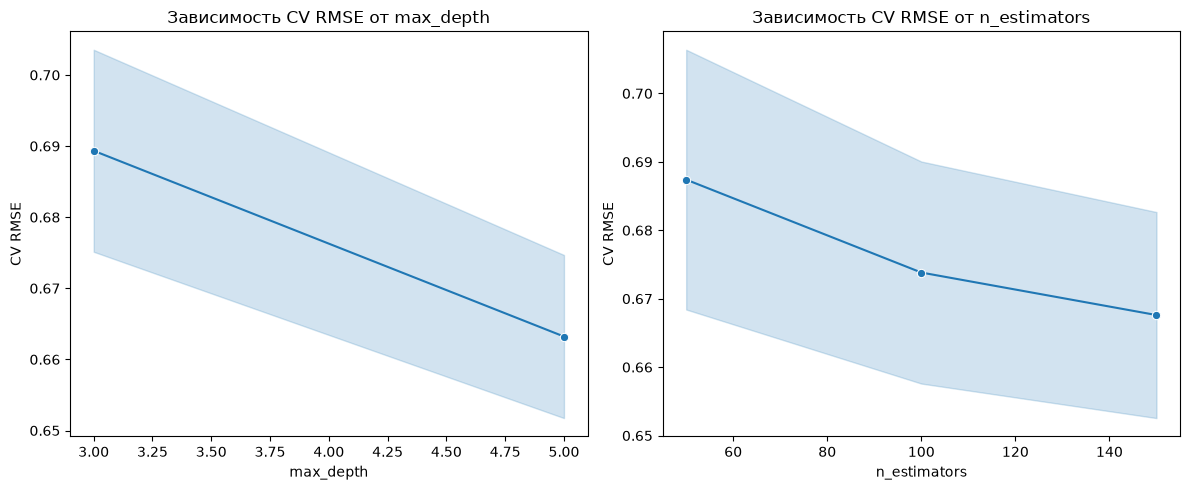

In [6]:
# Собираем результаты в DataFrame
results_df = pd.DataFrame(grid_search.cv_results_)

# Нас интересует зависимость от глубины (max_depth) и количества деревьев (n_estimators)
plt.figure(figsize=(12, 5))

# График 1: max_depth
plt.subplot(1, 2, 1)
sns.lineplot(data=results_df, x='param_max_depth', y=-results_df['mean_test_score'], marker='o', errorbar='sd')
plt.title('Зависимость CV RMSE от max_depth')
plt.xlabel('max_depth')
plt.ylabel('CV RMSE')

# График 2: n_estimators
plt.subplot(1, 2, 2)
sns.lineplot(data=results_df, x='param_n_estimators', y=-results_df['mean_test_score'], marker='o', errorbar='sd')
plt.title('Зависимость CV RMSE от n_estimators')
plt.xlabel('n_estimators')
plt.ylabel('CV RMSE')

plt.tight_layout()
plt.show()

**Вывод:** max_depth (глубина деревьев). На графике видно, что при max_depth=3 модель недообучается: CV RMSE ≈ 0.689. Увеличение глубины до 5 снижает RMSE до ≈ 0.663. Это объясняется тем, что более глубокие деревья способны улавливать сложные нелинейные взаимодействия между признаками (например, сочетание уровня алкоголя, кислотности и содержания серы), которые не видны при глубине 3. При дальнейшем увеличении глубины (7–10) можно ожидать начало переобучения — это подтверждается тем, что в Random Search лучшей оказалась конфигурация с max_depth=7, а не 10.

n_estimators (количество деревьев). С ростом числа деревьев CV RMSE падает, но убывающими темпами: с 0.687 при 50 деревьях до 0.673 при 100 и 0.668 при 150. Наблюдается классическое «насыщение»: каждое новое дерево в бустинге исправляет всё меньшие ошибки, и после 100–150 деревьев добавление новых даёт мало пользы. Зона недообучения — менее 100 деревьев, зона разумной сложности — 100–200 деревьев.

Общий вывод: оптимум для данной задачи находится в области max_depth = 5–7 и n_estimators = 150–250 при learning_rate ≈ 0.08–0.2. Именно такую конфигурацию нашёл Random Search, что подтверждает корректность визуального анализа.

## Анализ устойчивости

In [7]:
# Оцениваем лучшую модель с помощью cross_val_score и получаем массив из 5 фолдов
cv_scores_final = cross_val_score(best_grid_model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
cv_rmse_final = -cv_scores_final

print("CV RMSE по отдельным фолдам (Grid Search):")
for i, score in enumerate(cv_rmse_final):
    print(f"Фолд {i+1}: {score:.4f}")

print(f"\nСреднее: {cv_rmse_final.mean():.4f}")
print(f"Стандартное отклонение (разброс): {cv_rmse_final.std():.4f}")

CV RMSE по отдельным фолдам (Grid Search):
Фолд 1: 0.6430
Фолд 2: 0.6747
Фолд 3: 0.6382
Фолд 4: 0.6613
Фолд 5: 0.6209

Среднее: 0.6476
Стандартное отклонение (разброс): 0.0187


**Вывод:** Среднее CV RMSE = 0.6476, стандартное отклонение = 0.0187.

Разброс по фолдам небольшой (около ±0.02 от среднего, т.е. ~3%). Это говорит о хорошей устойчивости выбранной конфигурации: модель не сильно зависит от того, какие именно данные попали в обучение. Разница между лучшим (0.6209) и худшим (0.6747) фолдом — 0.0538 — объясняется тем, что в разных частях выборки могут быть разные пропорции «сложных» вин (например, с редкими оценками 3 или 9, которые модель предсказывает хуже).

Почему две модели с одинаковым средним качеством могут различаться по устойчивости: если бы у одной модели было среднее 0.6476 и std 0.005, а у другой — среднее 0.6476 и std 0.05, то вторая была бы «нестабильной»: на одних данных она работает отлично, на других — плохо. Для практики важнее не только среднее качество, но и предсказуемость. Модель с меньшим std надёжнее: её результат на новых данных будет ближе к ожидаемому.